# Part 2. Joining HOLC GRADE hex polygons to Ebird.  
This is where we'll join HOLC grade polygons to our grid. We'll be using Duckdb to save time and space. After this we will join it with our cleaned ebird shapefile.   

Before this we also need to join HOLC ids to the grids.  
There should be a shapefile of 100m Hexagons that are spaced 250 m from each other (to avoid spatial biases). 

Originally we also had other hexagon geojsons: 
[] 5 m  
[] 10 m 
[] 30 m 
[] 50 m 
[] 100 m *This is the one we'll be mostly using
[] 250 m 
[] 500 m 

But for our purposes, we will focus on using 100 m spaced hexagon file. 

For this section we will need: 

1. 100m spaced hexagon file 
2. Filtered ebird dataset from P1. 
3. holc shapefile
   

*Be sure to set up virtual environment + python interpreter (we're using Python 13+ and sf_env)

## Setting up

*You can ignore below if you already set up your virtual env and kernel.* 

1. First set up virtual env 

-  Open terminal, make sure to cd to project folder
-  Create the environment in terminal

```
conda create -n [INSERT_ENV_NAME] 
conda activate [INSERT_ENV_NAME] #activate your venv 
```

You should see in (INSERT_ENV_NAME) at the very beginning of your terminal command folder path

2. Install ipykernel 

```
conda install -n my_project ipykernel
```

Remember to always activate the correct environment before you install packages or before you run your Jupyter notebooks in VS Code!  Good luck!


## METHODS
1. Spatial join HOLC_grades to grids (100m) and then to ebird. Be sure each grid contains a unique ID 
2. Aggregate all parquets and then create new joined file for each unique ID 
3. Filters that remove hexagons: 

* NA in observations 
* They are spaced 250m apart at least (following more immediate habitat variates)
* Have at least 80% in ONE HOLC grade type (includes hexagons that overlap with other HOLC grades or are outside of HOLC grades)

In [1]:
#Install and Load required packages in the notebook's environment if not already installed.  This is a one-time step.
#%conda install ipykernel
#conda install -n sf_env ipykernel --update-deps --force-reinstall
#sf_env is the name of the conda environment
#%conda install duckdb pandas geopandas pyarrow
#%conda install shapely  
#Important for geometric operations

import duckdb
import pandas as pd
import geopandas as gpd
from pathlib import Path
from shapely.geometry import Point
#Connect to DuckDB (in-memory)

con = duckdb.connect()
#con  # Optional: Print the connection object

# Make sure your DuckDB connection has spatial capabilities
con.execute("INSTALL spatial")  # `INSTALL` can be skipped if already done
con.execute("LOAD spatial")

# If you'll be working with JSON files later
con.execute("INSTALL json")
con.execute("LOAD json")
con.execute("SELECT * FROM duckdb_extensions();")

In [2]:
import os 
os.getcwd()
os.chdir("/home/oliver/Documents/redlining/")

In [3]:
#read in shapfiles and holc data 
#we should have a cleaned version of SF holc data frm SF_HOLC_cleaning code 

holc = gpd.read_file("/home/oliver/Documents/redlining/data/SF/dependent_var/SF_HOLC_cleaned.geojson")
# Create a DuckDB table with geometry, setting the correct SRID
con.execute("CREATE OR REPLACE TABLE holc AS SELECT * FROM ST_READ('/home/oliver/Documents/redlining/data/SF/dependent_var/SF_HOLC_cleaned.geojson')")

In [4]:
# Read and reproject the data (100 m hexagon grids)
sf_100 = gpd.read_file("./data/SF/dependent_var/sf_100.shp")
holc_prj = holc.to_crs(sf_100.crs)

# Verify input data
print(f"HOLC CRS: {holc_prj.crs}")
print(f"Input geometry type: {holc_prj.geom_type.unique()}")


# Create temporary pandas DataFrame with explicitly selected columns
df = pd.DataFrame({
    'label': holc_prj['label'],
    'grade': holc_prj['grade'],
    'geom': holc_prj.geometry.apply(lambda x: x.wkb if x and x.is_valid else None)
})

# Drop existing table if it exists
con.execute("DROP TABLE IF EXISTS holc_prj")

# Create table from DataFrame

HOLC CRS: EPSG:32610
Input geometry type: <ArrowStringArray>
['MultiPolygon']
Length: 1, dtype: str


In [5]:
sf_100.explore()
#it should look like it's a whole grid covering redlined areas that is tesellated


In [6]:
# Verify input data is valid
print(f"HOLC CRS: {holc_prj.crs}")
print(f"SF_100 CRS: {sf_100.crs}")
print(f"HOLC geometry type: {holc_prj.geom_type.unique()}")
print(f"SF_100 geometry type: {sf_100.geom_type.unique()}")


HOLC CRS: EPSG:32610
SF_100 CRS: EPSG:32610
HOLC geometry type: <ArrowStringArray>
['MultiPolygon']
Length: 1, dtype: str
SF_100 geometry type: <ArrowStringArray>
['Polygon']
Length: 1, dtype: str


In [7]:
# ============================================================================
# Hexagons with >= 75% of their area in a single dominant HOLC grade
# ============================================================================
assert sf_100.crs.is_projected, "Need a projected CRS (meters) for area calcs"

THRESH = 0.75 # we end up with around 6k hexagons

hex_ = sf_100[["geometry"]].copy()
hex_["hex_idx"] = sf_100.index
hex_["hex_area"] = hex_.area

# Merge HOLC polygons by grade so neighbouring polygons with the same grade count together
holc_by_grade = holc_prj[["grade", "geometry"]].dissolve(by="grade").reset_index()

# Intersect hexagons with grades, then sum the overlap area per hexagon per grade
pieces = gpd.overlay(hex_, holc_by_grade, how="intersection", keep_geom_type=True)
pieces["piece_area"] = pieces.area

by_grade = (pieces.groupby(["hex_idx", "grade"], as_index=False)
                  .agg(piece_area=("piece_area", "sum"), hex_area=("hex_area", "first")))
by_grade["share_of_hex"] = by_grade["piece_area"] / by_grade["hex_area"]
# Share of only the HOLC-covered part of the hexagon (ignores area outside any grade)
by_grade["share_of_covered"] = (by_grade["piece_area"] /
                                by_grade.groupby("hex_idx")["piece_area"].transform("sum"))

# Keep the dominant grade for each hexagon
dominant = (by_grade.sort_values("piece_area", ascending=False)
                    .drop_duplicates("hex_idx"))

#>= 80% of the WHOLE hexagon is one grade
dom = dominant[dominant["share_of_hex"] >= THRESH]


summary = pd.DataFrame({
    #"completely_within": joined_data["grade"].value_counts(),
    ">=75% of hex":       dom["grade"].value_counts(),
}).fillna(0).astype(int).sort_index()
summary.loc["Total"] = summary.sum()
print(summary)

# GeoDataFrame 
joined_data_75 = sf_100.join(dom.set_index("hex_idx")[["grade", "share_of_hex"]], how="inner")


       >=75% of hex
grade              
A               436
B              1873
C              1879
D              1869
Total          6057


In [ ]:
""" #Ignore this, old version included completely within the polygons
# ============================================================================
# Verify hexagons are COMPLETELY within HOLC polygons
# ============================================================================

#This takes about 6 minutes (skip to spatial join chunk to load in if this is already run)
#We end up with 4000+ out of the original 7000
def filter_completely_within(hexagons, holc_polygons):
    
    #Keep only hexagons that are completely within a single HOLC grade.
    
    results = []
    
    for idx, hex_row in hexagons.iterrows():
        hex_geom = hex_row.geometry
        
        # Find which HOLC polygons this hexagon intersects
        intersecting = holc_polygons[holc_polygons.intersects(hex_geom)]
        
        if len(intersecting) == 0:
            # Not in any HOLC area - skip
            continue
        elif len(intersecting) == 1:
            # Check if COMPLETELY within (not just intersecting)
            holc_poly = intersecting.iloc[0]
            if holc_poly.geometry.contains(hex_geom):
                # Completely within one grade
                result_row = hex_row.copy()
                result_row['grade'] = holc_poly['grade']
                result_row['label'] = holc_poly['label']
                results.append(result_row)
        else:
            # Intersects multiple HOLC areas - skip
            continue
    
    if results:
        result_gdf = gpd.GeoDataFrame(results, crs=hexagons.crs)
        return result_gdf
    else:
        return gpd.GeoDataFrame(columns=hexagons.columns, crs=hexagons.crs)

# Apply the filter
joined_data_complete = filter_completely_within(sf_100, holc_prj)

print(f"\nOriginal hexagons: {len(sf_100)}")
print(f"Hexagons completely within single HOLC grade: {len(joined_data_complete)}")
print(f"Hexagons removed: {len(sf_100) - len(joined_data_complete)}")
joined_data_complete 

#Create one where it's not entirely inside the HOLC grades 
joined_data_incomplete = gpd.sjoin(sf_100, holc_prj, how="left", predicate="within")

joined_data_complete.plot()
joined_data_incomplete.plot()

"""


Original hexagons: 7983
Hexagons completely within single HOLC grade: 4410
Hexagons removed: 3573


,id,geometry,grade,label
0,299,"POLYGON ((543295.991 4180855.174, 543245.991 4...",B,B1
1,300,"POLYGON ((543295.991 4181028.379, 543245.991 4...",B,B1
2,301,"POLYGON ((543295.991 4181201.584, 543245.991 4...",B,B1
3,302,"POLYGON ((543295.991 4181374.79, 543245.991 41...",B,B1
4,362,"POLYGON ((543345.991 4180595.367, 543295.991 4...",B,B1
...,...,...,...,...
5499,16334,"POLYGON ((555845.991 4175745.624, 555795.991 4...",D,D16
5500,16397,"POLYGON ((555895.991 4175659.022, 555845.991 4...",D,D16
5501,16461,"POLYGON ((555945.991 4175572.419, 555895.991 4...",D,D16
5502,16462,"POLYGON ((555945.991 4175745.624, 555895.991 4...",D,D16


# Assign FID 

In [8]:


#run this if you already have it saved 
#joined_data = gpd.read_file("D:/Chapter1_LA_redlining/data/output/la_hex_100join_2_8_26.geojson")

#reset index to make FID column
joined_data_75 = joined_data_75.reset_index(drop=True)
joined_data_75['FID'] = joined_data_75.index + 1

#create a unique hex_id by combining FID and grade
joined_data_75['hex_id'] = joined_data_75['FID'].astype(str) + "_" + joined_data_75['grade'].astype(str) 

#Figure outwhat we have in there 
print(joined_data_75.head())

# If you want to write to database instead:
#joined_data.to_postgis("sf_hex_holc", con, if_exists="replace")

#we should drop index_right since it causes problems in a the spatial join later on 
#joined_data = joined_data.drop(columns=['index_right']) 


# Verify uniqueness
print(f"Total hexagons: {len(joined_data_75)}")
print(f"Unique FIDs: {joined_data_75['FID'].nunique()}")
print(f"All unique: {joined_data_75['FID'].nunique() == len(joined_data_75)}")



    id                                           geometry grade  share_of_hex  \
0  299  POLYGON ((543295.991 4180855.174, 543245.991 4...     B           1.0   
1  300  POLYGON ((543295.991 4181028.379, 543245.991 4...     B           1.0   
2  301  POLYGON ((543295.991 4181201.584, 543245.991 4...     B           1.0   
3  302  POLYGON ((543295.991 4181374.79, 543245.991 41...     B           1.0   
4  362  POLYGON ((543345.991 4180595.367, 543295.991 4...     B           1.0   

   FID hex_id  
0    1    1_B  
1    2    2_B  
2    3    3_B  
3    4    4_B  
4    5    5_B  
Total hexagons: 6057
Unique FIDs: 6057
All unique: True


In [22]:
os.getcwd()


'/home/oliver/Documents/redlining'

In [9]:
joined_data_75.to_file("./data/SF/sf_hex_100join.geojson")


# Load in eBird for joining

In [10]:
import duckdb
import os
from datetime import datetime

#This takes about 6 minutes
print("\n" + "="*80)
print("LOADING PARQUET AND CREATING SPATIAL DATA FOR JOINING")
print("="*80 + "\n")

# Create temp directory on D drive
temp_dir = "../data/output"
os.makedirs(temp_dir, exist_ok=True)

# Initialize connection with temp directory
con = duckdb.connect(":memory:")

# Load spatial extension
print("Loading spatial extension...")
con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

# Set up configuration
con.execute("SET threads TO 1;")
con.execute("SET memory_limit TO '16GB';")
con.execute(f"SET temp_directory='{temp_dir}';")  # Set temp directory

# ========================================================================
# 1. Load Parquet file
# ========================================================================
print("Loading parquet data...")
start_time = datetime.now()

con.execute("""
    CREATE OR REPLACE TABLE ebird AS
    SELECT * FROM read_parquet('/home/oliver/Documents/data/output/zf_SF_stat_trav_area_2010_2025.parquet');
""")

parquet_load_time = (datetime.now() - start_time).total_seconds()
print(f"Parquet loaded in {parquet_load_time:.2f} seconds")

# Check the data
row_count = con.execute("SELECT COUNT(*) FROM ebird").fetchone()[0]
print(f"Total rows: {row_count:,}")

# Show sample of column names
columns = con.execute("DESCRIBE ebird").fetchall()
print(f"\nColumns in dataset: {len(columns)}")
print("First 10 columns:", [c[0] for c in columns[:10]])


# ========================================================================
# 2. Create spatial points from lat/lon AND transform to EPSG:32610
# ========================================================================
print("\nCreating spatial points and transforming to EPSG:32610...")

# First, get distinct years
years = con.execute("""
    SELECT DISTINCT YEAR(observation_date) as year 
    FROM ebird 
    ORDER BY year
""").fetchall()
years = [y[0] for y in years]

print(f"Processing {len(years)} years: {years}")

# Create spatial table year by year with transformation in one step
for idx, year in enumerate(years):
    print(f"  Processing year {year} ({idx+1}/{len(years)})...")
    
    if idx == 0:
        # Create table with first year - transform directly
        con.execute(f"""
            CREATE TABLE ebird_transformed AS
            SELECT 
                *,
                ST_Transform(
                    ST_Point(longitude, latitude),
                    'EPSG:4326',
                    'EPSG:32610',
                     always_xy := true
                ) as geometry
            FROM ebird
            WHERE YEAR(observation_date) = {year}
              AND longitude IS NOT NULL 
              AND latitude IS NOT NULL
        """)
    else:
        # Insert remaining years
        con.execute(f"""
            INSERT INTO ebird_transformed
            SELECT 
                *,
                ST_Transform(
                    ST_Point(longitude, latitude),
                    'EPSG:4326',
                    'EPSG:32610',
                     always_xy := true
                ) as geometry
            FROM ebird
            WHERE YEAR(observation_date) = {year}
              AND longitude IS NOT NULL 
              AND latitude IS NOT NULL
        """)

print("✓ Spatial points created and transformed")

# Verify the transformation worked
spatial_count = con.execute("SELECT COUNT(*) FROM ebird_transformed").fetchone()[0]
print(f"Spatial points: {spatial_count:,}")

# Check extents to ensure transformation worked
print("\nVerifying transformation:")
extents = con.execute("""
    SELECT 
        MIN(ST_X(geometry)) as min_x,
        MAX(ST_X(geometry)) as max_x,
        MIN(ST_Y(geometry)) as min_y,
        MAX(ST_Y(geometry)) as max_y
    FROM ebird_transformed
""").df()
print(extents)

# Sample to verify (should show coordinates around 1.9M, 570K)
print("\nSample transformed points:")
print(con.execute("""
    SELECT 
        latitude, longitude,
        ST_X(geometry) as x_32610,
        ST_Y(geometry) as y_32610
    FROM ebird_transformed 
    LIMIT 5
""").df())


LOADING PARQUET AND CREATING SPATIAL DATA FOR JOINING

Loading spatial extension...
Loading parquet data...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Parquet loaded in 24.01 seconds
Total rows: 13,959,495

Columns in dataset: 47
First 10 columns: ['checklist_id', 'last_edited_date', 'country', 'country_code', 'state', 'state_code', 'county', 'county_code', 'iba_code', 'bcr_code']

Creating spatial points and transforming to EPSG:32610...
Processing 16 years: [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
  Processing year 2010 (1/16)...
  Processing year 2011 (2/16)...
  Processing year 2012 (3/16)...
  Processing year 2013 (4/16)...
  Processing year 2014 (5/16)...
  Processing year 2015 (6/16)...
  Processing year 2016 (7/16)...
  Processing year 2017 (8/16)...
  Processing year 2018 (9/16)...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  Processing year 2019 (10/16)...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (9 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  Processing year 2025 (16/16)...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

✓ Spatial points created and transformed
Spatial points: 13,959,495

Verifying transformation:
           min_x         max_x         min_y         max_y
0  415273.254158  558988.88996  4.114169e+06  4.190716e+06

Sample transformed points:
    latitude   longitude        x_32610       y_32610
0  37.775383 -122.481793  545635.802362  4.181020e+06
1  37.775383 -122.481793  545635.802362  4.181020e+06
2  37.775383 -122.481793  545635.802362  4.181020e+06
3  37.775383 -122.481793  545635.802362  4.181020e+06
4  37.775383 -122.481793  545635.802362  4.181020e+06


# Export out eBird hours for Efforts

In [13]:
# Only grab observation_hours, lat/long of checklists, and checklist_id
con.execute("""
    CREATE TABLE ebird_hours AS
    SELECT 
        checklist_id,
        observation_date,
        effort_hours,
        geometry 
    FROM ebird_transformed
""")
print("\n✓ Created ebird_hours table with selected columns")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


✓ Created ebird_hours table with selected columns


In [14]:
# Step 1: Remove exact duplicates
con.execute("""
    CREATE OR REPLACE TABLE ebird_hours AS
    SELECT DISTINCT
        checklist_id,
        observation_date,
        effort_hours,
        geometry 
    FROM ebird_hours
""")
print("✓ Removed duplicate rows")

# Step 2: Sum effort hours by checklist_id and observation_date
con.execute("""
    CREATE OR REPLACE TABLE ebird_hours AS
    SELECT 
        checklist_id,
        observation_date,
        SUM(effort_hours) as effort_hours,
        -- Keep one geometry per group (using ANY_VALUE or FIRST)
        ANY_VALUE(geometry) as geometry
    FROM ebird_hours
    GROUP BY checklist_id, observation_date
""")
print("✓ Aggregated effort hours by checklist_id and observation_date")

# Verify the results
stats = con.execute("""
    SELECT 
        COUNT(*) as total_rows,
        COUNT(DISTINCT checklist_id) as unique_checklists,
        COUNT(DISTINCT CONCAT(checklist_id, '|', observation_date)) as unique_combinations
    FROM ebird_hours
""").fetchone()

print(f"\nFinal stats:")
print(f"Total rows: {stats[0]:,}")
print(f"Unique checklist_ids: {stats[1]:,}")
print(f"Unique checklist_id + date combinations: {stats[2]:,}")




✓ Removed duplicate rows
✓ Aggregated effort hours by checklist_id and observation_date

Final stats:
Total rows: 50,960
Unique checklist_ids: 50,960
Unique checklist_id + date combinations: 50,960


In [15]:
#export to csv (use in check ebird_hours script)
# Export to CSV
con.execute("""
    COPY ebird_hours 
    TO './data/SF/ebird_hours_11.18.26.csv' 
    (HEADER, DELIMITER ',')
""")
print("✓ Exported to ebird_hours.csv")

✓ Exported to ebird_hours.csv


# Load eBird in Duckdb

In [16]:
#Load joined_data into duckdb
con.execute("""
    CREATE OR REPLACE TABLE joined_data AS
    SELECT *

            FROM ST_read('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/output/sf_hex_100join.geojson');
""")

# Show sample of column names
columns = con.execute("DESCRIBE joined_data").fetchall()
print(f"\nColumns in dataset: {len(columns)}")
print("First 10 columns:", [c[0] for c in columns[:40]])



# Check what CRS it has
print("Checking geometry properties...")
geom_info = con.execute("""
    SELECT 
        ST_GeometryType(geom) as geom_type,
        COUNT(*) as row_count
    FROM joined_data
    GROUP BY ST_GeometryType(geom)
""").df()
print(geom_info)




Columns in dataset: 6
First 10 columns: ['id', 'grade', 'label', 'FID', 'hex_id', 'geom']
Checking geometry properties...
  geom_type  row_count
0   POLYGON       4410


In [17]:
# Show sample of column names
columns = con.execute("DESCRIBE ebird_transformed").fetchall()
print(f"\nColumns in dataset: {len(columns)}")
print("First 10 columns:", [c[0] for c in columns[:100]])




Columns in dataset: 48
First 10 columns: ['checklist_id', 'last_edited_date', 'country', 'country_code', 'state', 'state_code', 'county', 'county_code', 'iba_code', 'bcr_code', 'usfws_code', 'atlas_block', 'locality', 'locality_id', 'locality_type', 'latitude', 'longitude', 'observation_date', 'time_observations_started', 'observer_id', 'observer_orcid_id', 'sampling_event_identifier', 'observation_type', 'protocol_name', 'protocol_code', 'project_names', 'project_identifiers', 'duration_minutes', 'effort_distance_km', 'effort_area_ha', 'number_observers', 'all_species_reported', 'group_identifier', 'checklist_comments', 'scientific_name', 'breeding_code', 'breeding_category', 'behavior_code', 'age_sex', 'observation_count', 'species_observed', 'effort_hours', 'effort_speed_kmph', 'hours_of_day', 'day_of_year', 'month', 'year', 'geometry']


In [ ]:
from shapely import wkb


ebird_transformed = con.execute("SELECT * FROM ebird_transformed").df()

ebird_transformed.head()


# Convert WKB bytearray to geometry
ebird = gpd.GeoDataFrame(
    ebird_transformed,
    geometry=ebird_transformed['geometry'].apply(lambda x: wkb.loads(bytes(x)))
)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [21]:
ebird_transformed

,checklist_id,last_edited_date,country,country_code,state,state_code,county,county_code,iba_code,bcr_code,...,observation_count,species_observed,effort_hours,effort_speed_kmph,hours_of_day,year,day_of_year,type,max_observations,geometry
0,S5805818,2025-03-20 13:59:39.670794,United States,US,California,US-CA,San Francisco,US-CA-075,NaN,<NA>,...,0,False,0.416667,0,16,2010,23,train,0,"[1, 1, 0, 0, 0, 212, 48, 234, 218, 84, 160, 32..."
1,G151830,2022-08-02 07:46:08.599587,United States,US,California,US-CA,San Francisco,US-CA-075,NaN,32,...,0,False,1.000000,0,16,2010,66,train,0,"[1, 1, 0, 0, 0, 205, 105, 98, 195, 183, 189, 3..."
2,S6101635,2021-04-01 02:38:29.728191,United States,US,California,US-CA,San Francisco,US-CA-075,NaN,32,...,0,False,0.500000,0,16,2010,66,train,0,"[1, 1, 0, 0, 0, 11, 225, 100, 51, 25, 188, 32,..."
3,S6848898,2021-04-01 02:38:29.728191,United States,US,California,US-CA,San Francisco,US-CA-075,NaN,32,...,0,False,0.166667,0,16,2010,246,train,0,"[1, 1, 0, 0, 0, 205, 105, 98, 195, 183, 189, 3..."
4,S6839594,2021-03-18 23:33:43.180338,United States,US,California,US-CA,San Francisco,US-CA-075,NaN,<NA>,...,0,False,0.166667,0,16,2010,246,train,0,"[1, 1, 0, 0, 0, 138, 233, 60, 155, 44, 170, 32..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5456778,S275169351,2025-09-24 00:30:19.912870,United States,US,California,US-CA,San Francisco,US-CA-075,NaN,32,...,0,False,0.116667,0,16,2025,266,train,0,"[1, 1, 0, 0, 0, 100, 204, 99, 32, 15, 168, 32,..."
5456779,S275134544,2025-09-25 19:29:51.007982,United States,US,California,US-CA,San Francisco,US-CA-075,NaN,<NA>,...,0,False,1.450000,0,16,2025,266,train,0,"[1, 1, 0, 0, 0, 241, 59, 15, 126, 157, 169, 32..."
5456780,S276677874,2025-10-11 23:53:19.886720,United States,US,California,US-CA,San Francisco,US-CA-075,NaN,32,...,0,False,0.083333,0,16,2025,266,train,0,"[1, 1, 0, 0, 0, 193, 137, 238, 107, 33, 186, 3..."
5456781,S275119627,2025-09-24 01:05:56.487233,United States,US,California,US-CA,San Francisco,US-CA-075,NaN,32,...,0,False,0.716667,0,16,2025,266,train,0,"[1, 1, 0, 0, 0, 6, 169, 20, 8, 181, 193, 32, 6..."


# Join HOLC and ebird

In [32]:
# Configure DuckDB to use all available cores
con.execute("SET threads TO 8")
con.execute("SET memory_limit = '12GB';")
con.execute("SET max_memory = '12GB';")
con.execute("SET preserve_insertion_order = false;")

print("Creating spatial indexes...")
con.execute("CREATE INDEX IF NOT EXISTS idx_ebird_geom ON ebird_transformed USING RTREE (geometry);")

print("Running parallel spatial join with aggregation by hexagon and species...")

con.execute("""
    CREATE OR REPLACE TABLE joined_data_all AS
    SELECT 
        h.hex_id,
        e.scientific_name,
        
        -- Aggregated observation data for this species in this hexagon
        SUM(e.max_observations) as total_max_observations,
        SUM(e.effort_hours) as total_effort_hours,
        COUNT(*) as num_checklists,
        COUNT(DISTINCT e.observation_date) as num_observation_days,
        
        -- Temporal information
        MIN(e.observation_date) as first_observed,
        MAX(e.observation_date) as last_observed,
        COUNT(DISTINCT YEAR(e.observation_date)) as num_years_observed,
        
        -- Hexagon geometry (keep for spatial analysis)
        h.geom as hexagon_geom,
        
        
    FROM ebird_transformed e
    INNER JOIN joined_data h
    ON ST_Intersects(h.geom, e.geometry)
    
    GROUP BY 
        h.hex_id,
        e.scientific_name,
        h.geom,
""")

print("✓ Join complete!")

# Verify results
print("\n" + "="*60)
print("="*60)




Creating spatial indexes...
Running parallel spatial join with aggregation by hexagon and species...
✓ Join complete!



# Effort Hours per Hexagon

In [35]:
#create another dataframe with total effort hours: 
# Configure DuckDB to use all available cores
con.execute("SET threads TO 8")
con.execute("SET memory_limit = '12GB';")
con.execute("SET max_memory = '12GB';")
con.execute("SET preserve_insertion_order = false;")

print("Creating spatial indexes...")
con.execute("CREATE INDEX IF NOT EXISTS idx_ebird_geom ON ebird_transformed USING RTREE (geometry);")

print("Running parallel spatial join with aggregation by hexagon and species...")

con.execute("""
    CREATE OR REPLACE TABLE joined_data_effort AS
    SELECT 
        h.hex_id,
        
        -- Aggregated observation data for this hexagon
        SUM(e.max_observations) as total_max_observations,
        SUM(e.effort_hours) as total_effort_hours,
        COUNT(*) as num_checklists,
        COUNT(DISTINCT e.observation_date) as num_observation_days,
        
        -- Temporal information
        MIN(e.observation_date) as first_observed,
        MAX(e.observation_date) as last_observed,
        COUNT(DISTINCT YEAR(e.observation_date)) as num_years_observed,
        
        -- Hexagon geometry (keep for spatial analysis)
        h.geom as hexagon_geom,
        
        
    FROM ebird_transformed e
    INNER JOIN joined_data h
    ON ST_Intersects(h.geom, e.geometry)
    
    GROUP BY 
        h.hex_id,
        h.geom,
""")

print("✓ Join complete!")

# Verify results
print("\n" + "="*60)
print("="*60)




Creating spatial indexes...
Running parallel spatial join with aggregation by hexagon and species...
✓ Join complete!



In [ ]:

# Sample records
print("\nSample Records (top 10 by observations):")
sample = con.execute("""
    SELECT *,
                     FROM joined_data_effort
    LIMIT 10
""").df()
print(sample)




Sample Records (top 10 by observations):
   hex_id  total_max_observations  total_effort_hours  num_checklists  \
0  2500_C                   163.0          316.816667            1571   
1  3573_D                   224.0         1935.750000            4191   
2  2607_C                   228.0          219.116667            2595   
3  1985_B                    50.0           24.933333             343   
4  3875_D                    47.0          224.300000             723   
5  3991_D                  2400.0         6864.466667           21180   
6  3626_D                   210.0          387.250000             647   
7  3960_D                    38.0          150.833333             290   
8  2311_C                     0.0            2.450000             147   
9   190_C                  4754.0        74501.866667           96994   

   num_observation_days first_observed last_observed  num_years_observed  \
0                     9     2015-02-10    2023-04-04                   3   
1 

In [ ]:
#Export out Effort Hours per Hexagon

# Export as Parquet (without geometry to save space)
print("Exporting to Parquet...")
con.execute("""
    COPY (SELECT * FROM joined_data_effort)
    TO './data/hexid_efforthours_11.11.26.csv'
    (FORMAT CSV);
""")


print("\n" + "="*80)
print("COMPLETE!")
print("="*80)




con.close()



Exporting to Parquet...
✓ Saved: ebird_holc_joined.parquet

COMPLETE!


# Test- joined with incomplete


In [23]:
import duckdb


#rset index to make FID column
joined_data_incomplete = joined_data_incomplete.reset_index(drop=True)
joined_data_incomplete['FID'] = joined_data_incomplete.index

#create a unique hex_id by combining FID and grade
joined_data_incomplete['hex_id'] = joined_data_incomplete['FID'].astype(str) + "_" + joined_data_incomplete['grade'].astype(str) 


# Make a copy and convert geometry to WKT (Well-Known Text)
joined_data_prepared = joined_data_incomplete.copy()
joined_data_prepared['geometry_wkt'] = joined_data_prepared['geometry'].apply(
    lambda x: x.wkt if x is not None else None
)

# Drop the original geometry column
joined_data_prepared = joined_data_prepared.drop(columns=['geometry'])


# Create a proper table with geometry
con.execute("""
    CREATE OR REPLACE TABLE joined_data_incomplete AS
    SELECT 
        *,
        ST_GeomFromText(geometry_wkt) as geometry
    FROM joined_data_prepared
""")



In [24]:
# See ALL columns
cols_h = con.execute("SELECT * FROM joined_data_incomplete LIMIT 0").df().columns.tolist()
cols_e = con.execute("SELECT * FROM ebird_transformed LIMIT 0").df().columns.tolist()

print("joined_data columns:", cols_h)
print("ebird_transformed columns:", cols_e)

# Check for geometry-related columns
geom_cols_h = [c for c in cols_h if 'geom' in c.lower()]
geom_cols_e = [c for c in cols_e if 'geom' in c.lower()]

print("\nGeometry columns in joined_data:", geom_cols_h)
print("Geometry columns in ebird_transformed:", geom_cols_e)

joined_data columns: ['id', 'index_right', 'area_id', 'city', 'state', 'city_survey', 'category', 'grade', 'label', 'residential', 'commercial', 'industrial', 'fill', 'FID', 'hex_id', 'geometry_wkt', 'geometry']
ebird_transformed columns: ['checklist_id', 'last_edited_date', 'country', 'country_code', 'state', 'state_code', 'county', 'county_code', 'iba_code', 'bcr_code', 'usfws_code', 'atlas_block', 'locality', 'locality_id', 'locality_type', 'latitude', 'longitude', 'observation_date', 'time_observations_started', 'observer_id', 'observer_orcid_id', 'sampling_event_identifier', 'observation_type', 'protocol_name', 'protocol_code', 'project_names', 'project_identifiers', 'duration_minutes', 'effort_distance_km', 'effort_area_ha', 'number_observers', 'all_species_reported', 'group_identifier', 'checklist_comments', 'scientific_name', 'breeding_code', 'breeding_category', 'behavior_code', 'age_sex', 'observation_count', 'species_observed', 'effort_hours', 'effort_speed_kmph', 'hours_of_

In [27]:

#con.execute("DROP VIEW joined_data_incomplete")

# Prepare your data
joined_data_prepared = joined_data_incomplete.copy()
joined_data_prepared['geometry_wkt'] = joined_data_prepared['geometry'].apply(
    lambda x: x.wkt if x is not None else None
)
joined_data_prepared = joined_data_prepared.drop(columns=['geometry'])


# Method 1: Using FROM pandas DataFrame directly
con.execute("""
    CREATE OR REPLACE TABLE joined_data_incomplete AS 
    SELECT * FROM joined_data_prepared
""")

# Add geometry column
con.execute("""
    ALTER TABLE joined_data_incomplete 
    ADD COLUMN geometry GEOMETRY
""")

con.execute("""
    UPDATE joined_data_incomplete
    SET geometry = ST_GeomFromText(geometry_wkt)
""")

# Drop the WKT column
con.execute("ALTER TABLE joined_data_incomplete DROP COLUMN geometry_wkt")

In [29]:
# Configure DuckDB to use all available cores
con.execute("SET threads TO 8")
con.execute("SET memory_limit = '12GB';")
con.execute("SET max_memory = '12GB';")
con.execute("SET preserve_insertion_order = false;")

print("Creating spatial indexes...")
con.execute("CREATE INDEX IF NOT EXISTS idx_ebird_geom ON ebird_transformed USING RTREE (geometry);")

print("Running parallel spatial join with aggregation by hexagon and species...")



con.execute("""
    CREATE OR REPLACE TABLE joined_data_all_incomplete AS
    SELECT 
        h.hex_id,
        e.scientific_name,
        
        -- Aggregated observation data for this species in this hexagon
        SUM(e.max_observations) as total_max_observations,
        COUNT(*) as num_checklists,
        COUNT(DISTINCT e.observation_date) as num_observation_days,
        SUM(e.effort_hours) as total_effort_hours,
        
        -- Temporal information
        MIN(e.observation_date) as first_observed,
        MAX(e.observation_date) as last_observed,
        COUNT(DISTINCT YEAR(e.observation_date)) as num_years_observed,
        
        -- Hexagon geometry (keep for spatial analysis)
        h.geometry as hexagon_geom,
        
        
    FROM ebird_transformed e
    INNER JOIN joined_data_incomplete h
    ON ST_Intersects(h.geometry, e.geometry)
    
    GROUP BY 
        h.hex_id,
        e.scientific_name,
        h.geometry,
""")

print("✓ Join complete!")

# Verify results
print("\n" + "="*60)
print("="*60)




Creating spatial indexes...
Running parallel spatial join with aggregation by hexagon and species...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

✓ Join complete!



In [ ]:
# Check spatial coverage
coverage = con.execute("""
    SELECT 
        COUNT(DISTINCT h.hex_id) as total_hexagons,
        COUNT(DISTINCT CASE WHEN e.geometry IS NOT NULL THEN h.hex_id END) as hexagons_with_birds,
        ROUND(100.0 * COUNT(DISTINCT CASE WHEN e.geometry IS NOT NULL THEN h.hex_id END) / 
              COUNT(DISTINCT h.hex_id), 2) as pct_coverage
    FROM joined_data h
    LEFT JOIN ebird_transformed e
        ON ST_Intersects(h.geom, e.geometry)
""").df()

print(coverage)

   total_hexagons  hexagons_with_birds  pct_coverage
0            4410                  742         16.83


In [33]:

# Overall statistics
overall_stats = con.execute("""
    SELECT 
        COUNT(*) as total_hexagon_species_combinations,
        COUNT(DISTINCT hex_id) as unique_hexagons,
        COUNT(DISTINCT scientific_name) as unique_species,
        SUM(total_max_observations) as grand_total_observations
    FROM joined_data_all
""").df()
print("\nOverall Statistics:")
print(overall_stats)



# Sample records
print("\nSample Records (top 10 by observations):")
sample = con.execute("""
    SELECT *,
                     FROM joined_data_all
    LIMIT 10
""").df()
print(sample)

#We end up with 478 species 



Overall Statistics:
   total_hexagon_species_combinations  unique_hexagons  unique_species  \
0                              155581              742             478   

   grand_total_observations  
0                  123850.0  

Sample Records (top 10 by observations):
   hex_id       scientific_name  total_max_observations  total_effort_hours  \
0  3932_C     Aegolius acadicus                     0.0            4.083333   
1  1999_C   Agelaius phoeniceus                     0.0          132.100000   
2  1514_C     Ardenna creatopus                     0.0            5.500000   
3   568_A     Ardenna creatopus                     0.0           17.100000   
4  4109_D     Ardenna creatopus                     0.0            0.083333   
5   473_B        Astur cooperii                     0.0            0.500000   
6  1167_B        Astur cooperii                     6.0            4.016667   
7  1514_C  Baeolophus inornatus                     0.0            5.500000   
8   874_B      Bu

In [ ]:

# Overall statistics
overall_stats = con.execute("""
    SELECT 
        COUNT(*) as total_hexagon_species_combinations,
        COUNT(DISTINCT hex_id) as unique_hexagons,
        COUNT(DISTINCT scientific_name) as unique_species,
        SUM(total_max_observations) as grand_total_observations
    FROM joined_data_all_incomplete
""").df()
print("\nOverall Statistics:")
print(overall_stats)



# Sample records
print("\nSample Records (top 10 by observations):")
sample = con.execute("""
    SELECT *,
    FROM joined_data_all_incomplete
    LIMIT 10
""").df()
print(sample)

#We end up with 478 species 



Overall Statistics:
   total_hexagon_species_combinations  unique_hexagons  unique_species  \
0                              291789              742             478   

   grand_total_observations  
0                  218007.0  

Sample Records (top 10 by observations):
   hex_id         scientific_name  total_max_observations  num_checklists  \
0     NaN  Zonotrichia albicollis                     0.0               9   
1     NaN    Aechmophorus clarkii                     0.0              91   
2  3316_C    Aeronautes saxatalis                    28.0             323   
3  1879_C     Agelaius phoeniceus                     0.0               2   
4     NaN     Anarhynchus nivosus                     0.0               4   
5     NaN       Ardenna creatopus                     0.0               6   
6  3316_C  Arenaria melanocephala                     0.0             315   
7   675_A        Calidris virgata                    23.0              23   
8  4793_D       Catharus guttatus  

In [30]:
# Check the data
row_count = con.execute("SELECT COUNT(*) FROM joined_data_all").fetchone()[0]
print(f"Total rows: {row_count:,}")

Total rows: 155,581


In [31]:
# Check the data
row_count = con.execute("SELECT COUNT(*) FROM joined_data_all_incomplete").fetchone()[0]
print(f"Total rows: {row_count:,}")

Total rows: 291,789


In [ ]:

# ========================================================================
# 7. Export results
# ========================================================================
print("\n" + "="*80)
print("EXPORTING RESULTS")
print("="*80 + "\n")


# Export as Parquet (without geometry to save space)
print("Exporting to Parquet...")
con.execute("""
    COPY (SELECT * FROM joined_data_all)
    TO '../data/output/ebird_hex_parquets_april2026/ebird_holc_joined_4_26_26.parquet'
    (FORMAT PARQUET);
""")
print("✓ Saved: ebird_holc_joined.parquet")


print("\n" + "="*80)
print("COMPLETE!")
print("="*80)


#Save the incomplete one too
# Export as Parquet (without geometry to save space)
print("Exporting to Parquet...")
con.execute("""
    COPY (SELECT * FROM joined_data_all_incomplete)
    TO '../data/output/ebird_hex_parquets_april2026/ebird_holc_joined_4_26_26_incomplete.parquet'
    (FORMAT PARQUET);
""")
print("✓ Saved: ebird_holc_joined.parquet")


con.close()



EXPORTING RESULTS

Exporting to Parquet...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

✓ Saved: ebird_holc_joined.parquet

COMPLETE!
Exporting to Parquet...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

✓ Saved: ebird_holc_joined.parquet


# Create Visual of the amount of sites

In [ ]:
#Create a bar graph of the amount of sites 
import matplotlib.pyplot as plt

# Define HOLC colors
holc_colors = {
    'A': '#9FE2BF',
    'B': '#6495ED', 
    'C': '#FFBF00',
    'D': '#DE3163'
}

# Get count of unique hexagons (sites) per HOLC grade
sites_by_grade = con.execute("""
    SELECT 
        holc_grade,
        COUNT(DISTINCT hex_id) as unique_sites
    FROM joined_data_all
    WHERE holc_grade IS NOT NULL
    GROUP BY holc_grade
    ORDER BY holc_grade
""").df()

print("\nUnique sites by HOLC grade:")
print(sites_by_grade)

# Create bar graph
fig, ax = plt.subplots(figsize=(10, 6))

# Create bars with HOLC colors
bars = ax.bar(
    sites_by_grade['holc_grade'], 
    sites_by_grade['unique_sites'],
    color=[holc_colors[grade] for grade in sites_by_grade['holc_grade']],
    edgecolor='black',
    linewidth=1.2
)

# Customize the plot
ax.set_xlabel('HOLC Grade', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Unique Sites', fontsize=12, fontweight='bold')
ax.set_title('Number of Unique Hexagon Sites by HOLC Grade', fontsize=14, fontweight='bold')

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add grid for easier reading
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Optional: Also show as percentage
total_sites = sites_by_grade['unique_sites'].sum()
sites_by_grade['percentage'] = (sites_by_grade['unique_sites'] / total_sites * 100).round(2)
print("\nWith percentages:")
print(sites_by_grade)

BinderException: Binder Error: Referenced column "holc_grade" not found in FROM clause!
Candidate bindings: "hex_id", "hexagon_geom", "last_observed", "total_max_observations"

LINE 6:     WHERE holc_grade IS NOT NULL
                  ^

# Stop here Move to P3

In [ ]:
#process data in chunks
import time

# Start timing
start_time = time.time()

# Make sure the output directory exists
output_dir = "G:/My Drive/Chapter1_SF_redlining_Rprj/data/output/ebird_hex_parquets_april2026"
os.makedirs(output_dir, exist_ok=True)



# Register your data with this connection if not already done
# Example: con.execute("CREATE TABLE data AS SELECT * FROM read_csv('your_data.csv')")

# Count total records to process
total_records = con.execute("SELECT COUNT(*) FROM ebird").fetchone()[0]
print(f"Total records to process: {total_records}")

# Function to process data in chunks
def process_chunks(connection, chunk_size=10000):  # Larger chunk size for efficiency
    offset = 0
    chunk_number = 0
    
    while True:
        query_start = time.time()
        print(f"Fetching chunk {chunk_number} (offset: {offset}, size: {chunk_size})...")
        
        # Read a chunk of data using the provided connection WITH OFFSET
        chunk = connection.execute(f"""
            SELECT 
                scientific_name,
                CAST(latitude AS DOUBLE) AS latitude, 
                CAST(longitude AS DOUBLE) AS longitude, 
                CAST(sampling_event_identifier AS VARCHAR) AS sampling_event_identifier, 
                CASE WHEN max_observations = '-inf' OR max_observations = 'inf' THEN NULL
                    ELSE CAST(max_observations AS INTEGER) 
                END AS max_observations
            FROM ebird
            LIMIT {chunk_size} OFFSET {offset}
        """).fetchall()
        
        query_end = time.time()
        print(f"  Query executed in {query_end - query_start:.2f} seconds")
        
        if not chunk:
            print("No more data to process")
            break
        
        print(f"  Processing {len(chunk)} records...")
        process_start = time.time()
        
        # Convert chunk to DataFrame
        df_chunk = pd.DataFrame(chunk, columns=['scientific_name', 'latitude', 'longitude', 
                                              'sampling_event_identifier', 'max_observations'])
        
        # Create GeoDataFrame from chunk
        gdf_chunk = gpd.GeoDataFrame(
            df_chunk, 
            geometry=gpd.points_from_xy(df_chunk.longitude, df_chunk.latitude),
            crs="EPSG:4326"
        )
        
        # Project to EPSG:32610
        gdf_chunk_projected = gdf_chunk.to_crs(epsg=32610)
        
        process_end = time.time()
        print(f"  Processing completed in {process_end - process_start:.2f} seconds")
        
        # Return the processed chunk and its number
        yield chunk_number, gdf_chunk_projected
        
        # Update for next iteration
        offset += chunk_size
        chunk_number += 1
        
        print(f"  Progress: {min(offset, total_records)}/{total_records} records ({min(offset, total_records)/total_records*100:.1f}%)")

        


Total records to process: 5456783


In [ ]:

#reproject sf_holc 
SF_HOLC = joined_data_complete.to_crs(epsg=32610)

#Make sure that ID column is unique and just combine with grade hex_id
SF_HOLC['hex_id'] = SF_HOLC['id'].astype(str) + "_" + SF_HOLC['grade'].astype(str) 

# Pre-project the hexagons once
print("Preparing hexagon data...")
SF_HOLC = SF_HOLC.to_crs(epsg=32610)

# Process chunks and join - pass the connection to the generator
total_chunks_processed = 0
total_points_processed = 0
spatial_join_time = 0

for chunk_number, gdf_chunk_projected in process_chunks(con):
    join_start = time.time()  
    # Define the output file name (this version has stationary counts and max counts for individual birds)
    output_file = os.path.join(output_dir, f"joined_data_chunk_{chunk_number}_station_max.parquet")
    
    # Check if the file already exists and remove it
    if os.path.exists(output_file):
        os.remove(output_file)
    
    # Perform spatial join for this chunk
    joined_chunk = gpd.sjoin(SF_HOLC, gdf_chunk_projected, how="left", predicate="intersects")
    
    join_end = time.time()
    join_duration = join_end - join_start
    spatial_join_time += join_duration
    
    # Save this chunk to a Parquet file
    joined_chunk.to_parquet(output_file)
    
    # Update statistics
    total_chunks_processed += 1
    total_points_processed += len(gdf_chunk_projected)
    
    print(f"Processed chunk {chunk_number}: {len(gdf_chunk_projected)} points, {len(joined_chunk)} matched.")
    print(f"  Spatial join took {join_duration:.2f} seconds")
    print(f"  Output size: {os.path.getsize(output_file) / (1024*1024):.2f} MB")

# Report final statistics
end_time = time.time()
total_time = end_time - start_time

print("\nProcessing Summary:")
print(f"Total time: {total_time:.2f} seconds ({total_time/60:.2f} minutes)")
print(f"Total chunks processed: {total_chunks_processed}")
print(f"Total points processed: {total_points_processed}")
print(f"Average time per point: {total_time/total_points_processed*1000:.2f} ms")
print(f"Time spent on spatial joins: {spatial_join_time:.2f} seconds ({spatial_join_time/total_time*100:.1f}% of total)")


#This Code works, takes about 13 minutes 

Preparing hexagon data...
Fetching chunk 0 (offset: 0, size: 10000)...


ConversionException: Conversion Error: Could not convert string '-inf' to INT32

LINE 7:                 CASE WHEN max_observations = '-inf' OR max_observations = 'inf' THEN NULL
                                                     ^

In [ ]:
# Get column names from the table
columns = con.execute("PRAGMA table_info(ebird)").fetchall()
for col in columns:
    print(col[1])  # Column name is usually in the second position

checklist_id
last_edited_date
country
country_code
state
state_code
county
county_code
iba_code
bcr_code
usfws_code
atlas_block
locality
locality_id
locality_type
latitude
longitude
observation_date
time_observations_started
observer_id
sampling_event_identifier
protocol_type
protocol_code
project_code
duration_minutes
effort_distance_km
effort_area_ha
number_observers
all_species_reported
group_identifier
trip_comments
scientific_name
breeding_code
breeding_category
behavior_code
age_sex
observation_count
species_observed
effort_hours
effort_speed_kmph
hours_of_day
year
day_of_year
max_observations


[]


Checking if it works here or in QGIS 


<>:5: SyntaxWarning: invalid escape sequence '\M'
<>:5: SyntaxWarning: invalid escape sequence '\M'
C:\Users\einna\AppData\Local\Temp\ipykernel_24236\2241849211.py:5: SyntaxWarning: invalid escape sequence '\M'
  parquet_file = "G:\My Drive\Chapter1_SF_redlining_Rprj\data\output\ebird_hex_parquets\joined_data_chunk_133_station_max.parquet"


         id                                           geometry  area_id  \
0       299  POLYGON ((543296.101 4180855.066, 543246.101 4...    710.0   
1       300  POLYGON ((543296.101 4181028.27, 543246.101 41...    710.0   
2       301  POLYGON ((543296.1 4181201.474, 543246.1 41812...    710.0   
3       302  POLYGON ((543296.099 4181374.678, 543246.099 4...    710.0   
4       362  POLYGON ((543346.103 4180595.26, 543296.102 41...    710.0   
...     ...                                                ...      ...   
7978  16526  POLYGON ((555996.089 4175832.097, 555946.089 4...      NaN   
7979  16589  POLYGON ((556046.089 4175572.289, 555996.089 4...      NaN   
7980  16590  POLYGON ((556046.089 4175745.495, 555996.089 4...      NaN   
7981  16653  POLYGON ((556096.089 4175658.892, 556046.089 4...      NaN   
7982  16718  POLYGON ((556146.089 4175745.494, 556096.089 4...      NaN   

               city state city_survey         category grade label  \
0     San Francisco    CA    

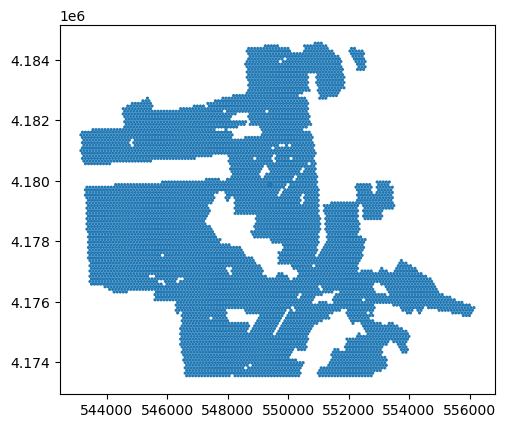

In [ ]:
#Check if join worked

import geopandas as gpd
# Read the Parquet file
parquet_file = "G:\My Drive\Chapter1_SF_redlining_Rprj\data\output\ebird_hex_parquets\joined_data_chunk_133_station_max.parquet"

gdf = gpd.read_parquet(parquet_file)

# Sample 10 rows randomly
print(gdf)
gdf.plot()  

gdf.explore()



#Okay seems to have worked-- now we gotta put it together with Hexagon IDs 
#check first though 
import folium

# Create base map centered on data
m = folium.Map()

# Add first layer
folium.GeoJson(
    gdf,
    name='ebird',
    style_function=lambda x: {'fillColor': 'red', 'color': 'red', 'weight': 1},
).add_to(m)

# Add second layer
folium.GeoJson(
    sf_100,
    name='grid',
    style_function=lambda x: {'fillColor': 'blue', 'color': 'blue', 'weight': 1},
).add_to(m)

# Add layer control
folium.LayerControl().add_to(m)
m


Stop here and move to P3. 

Just to note, the FID used to join from hexagons was from shapefile sf_100_holc_joined under FID and then in the new file put out is joined_data_chunk[number], and index_right ID column. 

Parquets are stored in the /data/output/ now but need to be moved to subfolder 


Now we want to sum and aggregate based on unique hexagon ID. We'll move to R to run inext for us: 

sf_inext_values_7.15.25.RMD 

In [ ]:
#aggregate and summarize on unique species for hex ID
gdf.head()  

,id,geometry,area_id,city,state,city_survey,category,grade,label,residential,commercial,industrial,fill,hex_id,index_right,scientific_name,latitude,longitude,sampling_event_identifier,max_observations
0,299,"POLYGON ((543296.101 4180855.066, 543246.101 4...",710.0,San Francisco,CA,True,Still Desirable,B,B1,True,False,False,#7cb5bd,299_B,NaN,None,NaN,NaN,None,NaN
1,300,"POLYGON ((543296.101 4181028.27, 543246.101 41...",710.0,San Francisco,CA,True,Still Desirable,B,B1,True,False,False,#7cb5bd,300_B,NaN,None,NaN,NaN,None,NaN
2,301,"POLYGON ((543296.1 4181201.474, 543246.1 41812...",710.0,San Francisco,CA,True,Still Desirable,B,B1,True,False,False,#7cb5bd,301_B,NaN,None,NaN,NaN,None,NaN
3,302,"POLYGON ((543296.099 4181374.678, 543246.099 4...",710.0,San Francisco,CA,True,Still Desirable,B,B1,True,False,False,#7cb5bd,302_B,NaN,None,NaN,NaN,None,NaN
4,362,"POLYGON ((543346.103 4180595.26, 543296.102 41...",710.0,San Francisco,CA,True,Still Desirable,B,B1,True,False,False,#7cb5bd,362_B,NaN,None,NaN,NaN,None,NaN


###TroubleShoot###
Try for only 100000 points 

In [ ]:
# from shapely.geometry import Point
# import os
# import geopandas as gpd
# import pandas as pd

# # Make sure the output directory exists
# output_dir = "G:/My Drive/Chapter1_SF_redlining_Rprj/data/output"
# os.makedirs(output_dir, exist_ok=True)

# # Function to process data in chunks
# def process_chunks(chunk_size=10000):  # Increased chunk size for efficiency
#     offset = 0
#     while True:
#         # Read a chunk of data
#         chunk = con.execute(f"""
#             SELECT 
#                 scientific_name,
#                 CAST(latitude AS DOUBLE) AS latitude, 
#                 CAST(longitude AS DOUBLE) AS longitude, 
#                 CAST(sampling_event_identifier AS VARCHAR) AS sampling_event_identifier, 
#                 CAST(observation_count AS INTEGER) AS observation_count
#             FROM ebird
#         """).fetchall()
        
#         if not chunk:
#             break
        
#         # Convert chunk to DataFrame
#         df_chunk = pd.DataFrame(chunk, columns=['scientific_name', 'latitude', 'longitude', 
#                                               'sampling_event_identifier', 'observation_count'])
        
#         # Create GeoDataFrame from chunk
#         gdf_chunk = gpd.GeoDataFrame(
#             df_chunk, 
#             geometry=gpd.points_from_xy(df_chunk.longitude, df_chunk.latitude),
#             crs="EPSG:4326"
#         )
        
#         # Project to EPSG:26910
#         gdf_chunk_projected = gdf_chunk.to_crs(epsg=26910)
        
#         # Yield the projected chunk
#         yield gdf_chunk_projected
        
#         offset += chunk_size


In [ ]:

# # First, ensure SF_HOLC has a unique ID for each hexagon
# # If it doesn't already have one, create it
# SF_HOLC = joined_data.to_crs(epsg=26910)

# if 'hex_id' not in SF_HOLC.columns:
#     SF_HOLC['hex_id'] = range(1, len(SF_HOLC) + 1)

# # Keep only essential hexagon columns to make the output cleaner
# hex_columns_to_keep = ['hex_id', 'geometry']  # Add any other hexagon attributes you need
# SF_HOLC_slim = SF_HOLC[hex_columns_to_keep]

# # Process chunks and join
# for i, gdf_chunk_projected in enumerate(process_chunks()):
#     # Define the output file name
#     output_file = os.path.join(output_dir, f"joined_data_chunk_{i}.parquet")
    
#     # Check if the file already exists and remove it
#     if os.path.exists(output_file):
#         os.remove(output_file)
#         print(f"Removed existing file: {output_file}")
    
#     # Perform spatial join for this chunk
#     # Use 'within' to only include observations inside hexagons to prevent double counting
#     joined_chunk = gpd.sjoin(gdf_chunk_projected, SF_HOLC_slim, how="inner", predicate="within")
    
#     # The joined data now includes all the original point attributes plus the hex_id
#     # 'index_right' is also included which is the index of the matching hexagon
    
#     # Save this chunk to a Parquet file
#     joined_chunk.to_parquet(output_file)
#     print(f"Processed and saved chunk {i}")

# print("Spatial join completed and saved in Parquet chunks.")

In [ ]:


# # 3. Create spatial points from checklist lat/long coordinates
# print("Creating spatial points...")
# start_time = datetime.now()
# con.execute("""
#     CREATE OR REPLACE TABLE ebird AS
#     SELECT 
#         *,
#         ST_Point("longitude", "latitude") AS geom
#     FROM ebird
# """)

# points_creation_time = (datetime.now() - start_time).total_seconds()
# print(f"Points created in {points_creation_time:.2f} seconds")



In [ ]:
# # Get the CRS information from holc_prj

# shapefile_path = "G:/My Drive/Chapter1_SF_redlining_Rprj/data/output/sf_hex_holc_joined.shp"

# print("Checking holc projection...")
# crs_query = f"""
#     SELECT
#         layers[1].geometry_fields[1].crs.auth_name as auth_name,
#         layers[1].geometry_fields[1].crs.auth_code as auth_code
#     FROM st_read_meta('{shapefile_path}')
# """

# # Replace 'path_to_holc_prj_file' with the actual path to your holc_prj file
# # For example:
# # crs_query = """
# #     SELECT
# #         layers[1].geometry_fields[1].crs.auth_name as auth_name,
# #         layers[1].geometry_fields[1].crs.auth_code as auth_code
# #     FROM st_read_meta('../../data/holc.shp')
# # """

# crs_result = con.execute(crs_query).fetchone()
# print(crs_result)




In [ ]:
# Then create and reproject the ebird points
con.execute(f"""
    CREATE OR REPLACE TABLE ebird_prj AS
    SELECT *,
        ST_Transform(
            ST_GeomFromText(
                'POINT(' || longitude || ' ' || latitude || ')'
            ), 'EPSG:4326', 'EPSG:26910', always_xy := true
        ) AS geom
    FROM ebird
""")

points_creation_time = (datetime.now() - start_time).total_seconds()
print(f"Points created and reprojected in {points_creation_time:.2f} seconds")

In [ ]:
    # Option 2: Query the data from DuckDB and convert to GeoPandas DataFrame
    # Assuming 'your_spatial_data' is the table created in DuckDB
df = con.execute("SELECT * FROM your_spatial_data;").fetchdf()
gdf = gpd.GeoDataFrame(df, geometry=gpd.GeoSeries.from_wkb(df['geom'])) # Assuming 'geom' column contains WKB geometry

# Display the shapefile
gdf.plot()


In [ ]:
# 4. Perform the spatial join between points and hexagons
print("Performing spatial join...")

start_time = datetime.now()

con.execute(f"""
    CREATE OR REPLACE TABLE ebird_hex_holc AS
    SELECT 
        c.*,
        h.*
    FROM ebird_prj c
    JOIN holc h ON ST_Within(c.geom_1, h.geom);
""")


join_time = (datetime.now() - start_time).total_seconds()
print(f"Spatial join completed in {join_time:.2f} seconds")




    SELECT zipcodes.zipcode, count(*) as numpoints
    FROM zipcodes
    JOIN buildings ON ST_Contains(zipcodes.geom, buildings.geom)
    GROUP BY zipcodes.zipcode
    """

In [ ]:
# 4. Perform the spatial join between points and hexagons
print("Performing spatial join...")

start_time = datetime.now()

con.execute(f"""
    CREATE OR REPLACE TABLE ebird_test AS
    SELECT c.scientific_name, count(*) as numpoints
    FROM ebird_prj c
    JOIN holc h ON ST_Intersects(c.geom_1, h.geom)
            GROUP BY c.scientific_name;
""")


join_time = (datetime.now() - start_time).total_seconds()
print(f"Spatial join completed in {join_time:.2f} seconds")




In [ ]:
con.table("ebird_test")

In [ ]:
m = folium.Map(zoom_start=10)

import folium

folium.GeoJson(
    joined_data.to_json(),
    name="Shapefile Layer 1",
    style_function=lambda x: {"fillColor": "blue", "color": "blue", "weight": 1, "fillOpacity": 0.5}
).add_to(m)

m



In [ ]:
folium.GeoJson(
    joined_data.to_json(),
    name="Shapefile Layer 1",
    style_function=lambda x: {"fillColor": "blue", "color": "blue", "weight": 1, "fillOpacity": 0.5}
).add_to(m)

In [ ]:
query = f"""
            SELECT * FROM ebird_hex_holc LIMIT 10
                           """

# 5. Check results
result_count = con.execute(query).fetchall()
result_count

In [ ]:

# 6. Export the results if needed
print("Exporting results...")
start_time = datetime.now()
output_dir = "G:/My Drive/Chapter1_SF_redlining_Rprj/data/output"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "ebird_hex_holc.csv")

con.execute(f"""
    COPY (
        SELECT * FROM checklist_holc_join
    ) TO '{output_path}' (HEADER, DELIMITER ',');
""")

export_time = (datetime.now() - start_time).total_seconds()

print(f"Results exported to {output_path} in {export_time:.2f} seconds")

# Total execution time
print(f"\nTotal processing time: {csv_load_time + shp_load_time + points_creation_time + join_time + export_time:.2f} seconds")

In [ ]:
import duckdb
import os
from datetime import datetime

# Initialize connection
con = duckdb.connect(":memory:")

# Load spatial extension
con.execute("INSTALL spatial; LOAD spatial;")

# Set paths
input_csv = "G:/My Drive/Chapter1_SF_redlining_Rprj/data/output/checklist_holc_joined.csv"
output_dir = "G:/My Drive/Chapter1_SF_redlining_Rprj/data/output"
os.makedirs(output_dir, exist_ok=True)

# Load the joined data
print("Loading joined data...")
start_time = datetime.now()
con.execute(f"""
    CREATE OR REPLACE TABLE checklist_holc_join AS
    SELECT * FROM read_csv_auto('{input_csv}', header=True, ignore_errors=True);
""")
load_time = (datetime.now() - start_time).total_seconds()
print(f"Data loaded in {load_time:.2f} seconds")

# Load the shapefile to get access to all hexagons and their grade percentages
shapefile_path = "G:/My Drive/Chapter1_SF_redlining_Rprj/data/output/sf_hex_holc_joined.shp"
con.execute(f"""
    CREATE OR REPLACE TABLE holc_hex AS
    SELECT * FROM ST_Read('{shapefile_path}');
""")

# Find hexagons that are 100% within one HOLC grade
print("Finding hexagons with 100% in one grade...")
start_time = datetime.now()

con.execute("""
    CREATE OR REPLACE TABLE pure_grade_hexagons AS
    SELECT 
        hex_id,
        CASE
            WHEN pct_A = 100 THEN 'A'
            WHEN pct_B = 100 THEN 'B'
            WHEN pct_C = 100 THEN 'C'
            WHEN pct_D = 100 THEN 'D'
            ELSE 'Mixed'
        END AS holc_grade
    FROM holc_hex
    WHERE pct_A = 100 OR pct_B = 100 OR pct_C = 100 OR pct_D = 100;
""")

pure_hex_time = (datetime.now() - start_time).total_seconds()
print(f"Pure grade hexagon identification completed in {pure_hex_time:.2f} seconds")


con.execute("SELECT * FROM pure_grade_hexagons LIMIT 5;").fetchall()

In [ ]:

# Count pure grade hexagons by grade
con.execute("""
    SELECT holc_grade, COUNT(*) as count
    FROM pure_grade_hexagons
    GROUP BY holc_grade
    ORDER BY holc_grade;
""")

# Now identify hexagons that have >2 unique species AND are 100% in one grade
print("Finding hexagons with >2 unique species in pure grade areas...")
start_time = datetime.now()

con.execute("""
    CREATE OR REPLACE TABLE pure_grade_species_counts AS
    SELECT 
        c.hex_id,
        p.holc_grade,
        COUNT(DISTINCT c.scientific_name) AS unique_species_count
    FROM checklist_holc_join c
    JOIN pure_grade_hexagons p ON c.hex_id = p.hex_id
    WHERE c.scientific_name IS NOT NULL
    GROUP BY c.hex_id, p.holc_grade
    HAVING COUNT(DISTINCT c.scientific_name) > 2;
""")

species_count_time = (datetime.now() - start_time).total_seconds()
print(f"Species counting completed in {species_count_time:.2f} seconds")

# Count qualifying hexagons by grade
con.execute("""
    SELECT holc_grade, COUNT(*) as count, AVG(unique_species_count) as avg_species
    FROM pure_grade_species_counts
    GROUP BY holc_grade
    ORDER BY holc_grade;
""")

con.execute("SELECT * FROM pure_grade_species_counts LIMIT 5;").fetchall()

In [ ]:


# Create filtered dataset with only observations from qualifying hexagons
print("Creating filtered dataset...")
start_time = datetime.now()
con.execute("""
    CREATE OR REPLACE TABLE filtered_pure_grade_checklist AS
    SELECT 
        c.*,
        p.holc_grade AS pure_holc_grade
    FROM checklist_holc_join c
    JOIN pure_grade_species_counts p ON c.hex_id = p.hex_id;
""")
filter_time = (datetime.now() - start_time).total_seconds()
print(f"Filtering completed in {filter_time:.2f} seconds")




In [ ]:

# Count observations in the filtered dataset
obs_count = con.execute("SELECT COUNT(*) FROM filtered_pure_grade_checklist").fetchone()[0]
print(f"Filtered dataset contains {obs_count:,d} observations")

# Export filtered observations
print("Exporting filtered observations...")
start_time = datetime.now()
filtered_obs_path = os.path.join(output_dir, "filtered_pure_grade_observations.csv")

con.execute(f"""
    COPY (
        SELECT * FROM filtered_pure_grade_checklist
    ) TO '{filtered_obs_path}' (HEADER, DELIMITER ',');
""")
export_obs_time = (datetime.now() - start_time).total_seconds()
print(f"Filtered observations exported in {export_obs_time:.2f} seconds")

# Export summary of qualifying hexagons
print("Exporting hexagon summary...")
start_time = datetime.now()
hex_summary_path = os.path.join(output_dir, "pure_grade_hexagons_species_summary.csv")




In [ ]:

con.execute(f"""
    COPY (
        SELECT 
            p.hex_id,
            p.holc_grade,
            p.unique_species_count,
            COUNT(DISTINCT c.scientific_name) AS verified_species_count,
            COUNT(c.observation_count) AS observation_count
        FROM pure_grade_species_counts p
        JOIN checklist_holc_join c ON p.hex_id = c.hex_id
        GROUP BY p.hex_id, p.holc_grade, p.unique_species_count
        ORDER BY p.holc_grade, p.unique_species_count DESC
    ) TO '{hex_summary_path}' (HEADER, DELIMITER ',');
""")
export_summary_time = (datetime.now() - start_time).total_seconds()
print(f"Hexagon summary exported in {export_summary_time:.2f} seconds")

# Create a spatial file with the qualifying hexagons
print("Creating spatial file of qualifying pure grade hexagons...")
start_time = datetime.now()

# Create a filtered shapefile with only qualifying hexagons
con.execute("""
    CREATE OR REPLACE TABLE filtered_pure_grade_hex AS
    SELECT 
        h.*,
        p.holc_grade AS pure_holc_grade,
        p.unique_species_count
    FROM holc_hex h
    JOIN pure_grade_species_counts p ON h.hex_id = p.hex_id;
""")

# Export to GeoJSON
filtered_geo_path = os.path.join(output_dir, "pure_grade_hexagons_with_species.geojson")
con.execute(f"""
    COPY (
        SELECT * FROM filtered_pure_grade_hex
    ) TO '{filtered_geo_path}' (FORMAT GDAL, DRIVER 'GeoJSON');
""")

spatial_export_time = (datetime.now() - start_time).total_seconds()
print(f"Spatial file created in {spatial_export_time:.2f} seconds")

# Total execution time
total_time = load_time + pure_hex_time + species_count_time + filter_time + export_obs_time + export_summary_time + spatial_export_time
print(f"\nTotal processing time: {total_time:.2f} seconds")

In [ ]:
import folium

# Create base map centered on data
m = folium.Map()

# Add first layer
folium.GeoJson(
    holc,
    name='holc',
    style_function=lambda x: {'fillColor': 'red', 'color': 'red', 'weight': 1},
    tooltip=folium.GeoJsonTooltip(fields=['label'])
).add_to(m)

# Add second layer
folium.GeoJson(
    sf_100,
    name='Layer 2',
    style_function=lambda x: {'fillColor': 'blue', 'color': 'blue', 'weight': 1},
).add_to(m)

# Add layer control
folium.LayerControl().add_to(m)

# Display map
m

In [ ]:
# Set up parallelism
con.execute("SET threads TO 8;")
con.execute("SET memory_limit TO '32GB';")


# Path to the directory containing shapefiles
shapefile_directory = Path("G:/My Drive/Chapter1_SF_redlining_Rprj/data/dependent_var/sf_hex")

# Find all shapefiles in the directory
shapefiles = list(shapefile_directory.glob("*.shp"))

# Loop through each shapefile
for shapefile in shapefiles:
    # Get table name from the filename (without extension)
    table_name = shapefile.stem
    
    # Use DuckDB's ST_READ function to directly read the shapefile into DuckDB
    con.execute(f"""
        CREATE TABLE {table_name} AS 
        SELECT * FROM ST_READ('{str(shapefile)}')
    """)
    
    print(f"Loaded {shapefile.name} into DuckDB as table '{table_name}'.")


In [ ]:
#troubleshoot 
from datetime import datetime

# Set up parallelism
con.execute("SET threads TO 8;")  # Adjust the number based on your CPU cores

# Set up memory limit
con.execute("SET memory_limit TO '32GB';")  # Adjust based on your system's available memory

# Get list of all tables in DuckDB - using the correct schema reference
tables = con.execute("SELECT table_name FROM information_schema.tables").fetchall()
grid_tables = [table[0] for table in tables if table[0] != 'holc']  # Exclude the HOLC table

print(f"Found {len(grid_tables)} grid tables to process")

# Track overall processing time
overall_start_time = datetime.now()
print(f"Starting spatial joins for {len(grid_tables)} grid tables at {overall_start_time.strftime('%H:%M:%S')}")


print(grid_tables)

In [ ]:
# View table schema
con.execute("DESCRIBE sf_10 ").fetchall()

# Or get column names and types
con.execute("""
    SELECT column_name, data_type 
    FROM information_schema.columns 
    WHERE table_name='sf_500'
""").fetchall()

In [ ]:
holc.columns
#sf_500.columns


#Test usigng SF_500
# Get list of grid tables
tables = con.execute("SELECT table_name FROM information_schema.tables").fetchall()
grid_tables = [table[0] for table in tables if table[0] != 'holc_prj']

print(f"Found {len(grid_tables)} grid tables to process")

# Check CRS of a GeoDataFrame

In [ ]:
# Read and reproject the data 
sf_500 = gpd.read_file("G:/My Drive/Chapter1_SF_redlining_Rprj/data/dependent_var/sf_hex/SF_100.shp")
holc_prj = holc.to_crs(sf_100.crs)

# Create temporary pandas DataFrame with explicitly selected columns
df = pd.DataFrame({
    'label': holc_prj['label'],
    'grade': holc_prj['grade'], 
    'geom': holc_prj.geometry.apply(lambda x: x.wkb if x and x.is_valid else None)
})

# Drop existing table if it exists
con.execute("DROP TABLE IF EXISTS holc_prj")

# Create table with proper geometry handling
con.execute("""
CREATE TABLE holc_prj AS 
SELECT 
    label,
    grade,
    CAST(ST_GeomFromWKB(geom) AS GEOMETRY) as geom 
FROM df
WHERE geom IS NOT NULL
""")

# Create spatial index
con.execute("""
CREATE INDEX holc_spatial_idx ON holc_prj(geom);
""")

# Verify table creation
print("\nVerifying holc_prj table:")
print("Row count:", con.execute("SELECT COUNT(*) FROM holc_prj").fetchone()[0])
print("Geometry type:", con.execute("SELECT ST_GeometryType(geom) FROM holc_prj LIMIT 1").fetchone()[0])
print("Valid geometries:", con.execute("SELECT COUNT(*) FROM holc_prj WHERE ST_IsValid(geom)").fetchone()[0])

In [ ]:
from datetime import datetime
import pandas as pd

# Track overall processing time
overall_start_time = datetime.now()
print(f"Starting spatial joins at {overall_start_time.strftime('%H:%M:%S')}")

# Loop through each grid table
for i, grid_table in enumerate(grid_tables):
    joined_table_name = f"{grid_table}_holc_joined"
    
    print(f"\nProcessing table {i+1}/{len(grid_tables)}: {grid_table}")
    start_time = datetime.now()
    
    # Check input tables first
    grid_count = con.execute(f"SELECT COUNT(*) FROM {grid_table}").fetchone()[0]
    holc_count = con.execute("SELECT COUNT(*) FROM holc_prj").fetchone()[0]
    print(f"Input counts - Grid: {grid_count}, HOLC: {holc_count}")
    
    if grid_count == 0 or holc_count == 0:
        print("Warning: One or both input tables are empty!")
        continue
    
    # First, drop the existing table
    con.execute(f"DROP TABLE IF EXISTS {joined_table_name}")

    # Perform spatial join with ST_Intersects instead of ST_Within
    try:
        con.execute(f"""
        CREATE TABLE {joined_table_name} AS
        SELECT 
            g.*, 
            h.label,
            h.grade,
            h.geom 
        FROM 
            {grid_table} g
        JOIN 
            holc_prj h
        ON 
            ST_Intersects(g.geom, h.geom)
        WHERE
            g.geom IS NOT NULL 
            AND h.geom IS NOT NULL
        """)
        
        # Count rows in the new joined table
        result = con.execute(f"SELECT COUNT(*) FROM {joined_table_name}")
        join_count = result.fetchone()[0]
        
        # Calculate and print execution time for this join
        join_end_time = datetime.now()
        join_execution_time = (join_end_time - start_time).total_seconds()
        print(f"Created joined table: {joined_table_name} with {join_count} rows")
        print(f"Spatial join execution time: {join_execution_time:.2f} seconds")
        
        # Validate join results
        if join_count == 0:
            print("Warning: Join produced no results!")
            # Optional: Print sample geometries to debug
            print("\nSample grid geometry:")
            print(con.execute(f"SELECT ST_AsText(geom) FROM {grid_table} LIMIT 1").fetchone())
            print("\nSample HOLC geometry:")
            print(con.execute("SELECT ST_AsText(geom) FROM holc_prj LIMIT 1").fetchone())
            
    except Exception as e:
        print(f"Error performing spatial join: {str(e)}")

In [ ]:
# Check geometry validity
print("\nChecking geometry validity...")
con.execute(f"""
    SELECT COUNT(*) 
    FROM {grid_table} 
    WHERE NOT ST_IsValid(geom)
""").fetchone()[0]

con.execute("""
    SELECT COUNT(*) 
    FROM holc_prj 
    WHERE NOT ST_IsValid(geom)
""").fetchone()[0]

In [ ]:
import duckdb
from datetime import datetime
start_time = datetime.now() #record start time 
data = con.read_csv("G:/My Drive/Chapter1_SF_redlining_Rprj/data/output/checklists-zf_breed_us-sf_2.6.24.csv", strict_mode=False)
print(con.sql("select count(*) from data"))
end_time = datetime.now() #end time
execution_time = (end_time - start_time).total_seconds()
print(f"Execution time: {execution_time} seconds")
#This took around 1 min to run


In [ ]:
#print(duckdb.sql("create table ebird as select * from data"))
print(con.sql("select * from data limit 10;"))
con.execute("CREATE TABLE ebird AS SELECT * FROM data")


In [ ]:
print(con.sql("select * from sf_100_holc_joined limit 10;"))

In [ ]:

# Set up parallelism
con.execute("SET threads TO 8;")  # Adjust the number based on your CPU cores

# Set up memory and temporary directory (adjust as needed)
con.execute("SET memory_limit TO '32GB';")

start_time = datetime.now()  # record start time


# Print the count of rows in the new table
result = con.execute("SELECT COUNT(*) FROM data")
print(f"Number of rows in selected_data: {result.fetchone()[0]}")
end_time = datetime.now()  # end time
execution_time = (end_time - start_time).total_seconds()
print(f"Execution time: {execution_time} seconds")


#This takes about 40 minutes to run on high performance machine
#Actually it took 63 seconds the second time.

In [ ]:
# Execute the query and fetch the results as a pandas DataFrame

query = "SELECT * FROM data LIMIT 1000"
df = con.execute(query).df()

# Print the DataFrame
print("\nFirst 10 rows of the table:")
print(df)

# Close the connection
#con.close()

In [ ]:
def process_chunks_by_grid(chunk_size=100000, grid_tables=None):
    """Process eBird data in chunks and perform spatial joins with multiple grid tables."""
    offset = 0
    processed_count = 0
    start_time = datetime.now()
    
    print(f"Starting processing at {start_time.strftime('%H:%M:%S')}")

    # Make sure spatial extension is loaded
    con.execute("LOAD spatial;")

    # Create result tables if they don't exist
    for table in grid_tables:
        con.execute(f"""
        CREATE TABLE IF NOT EXISTS {table}_results (
            scientific_name VARCHAR,
            sampling_event_identifier VARCHAR,
            observation_count INTEGER,
            label VARCHAR,
            grade VARCHAR,
            geom GEOMETRY
        )
        """)
        
    while True:
        chunk_start = datetime.now()
        try:
            # Read and transform chunk with proper spatial functions
            chunk_query = f"""
                WITH point_data AS (
                    SELECT 
                        scientific_name, 
                        sampling_event_identifier,
                        observation_count,
                        longitude,
                        latitude
                    FROM data
                    LIMIT {chunk_size} OFFSET {offset}
                ),
                points_with_srid AS (
                    SELECT *,
                        ST_GeomFromText(
                            'POINT(' || longitude || ' ' || latitude || ')',
                            4326
                        ) as geom_4326
                    FROM point_data
                )
                SELECT 
                    scientific_name,
                    sampling_event_identifier,
                    observation_count,
                    ST_Transform(geom_4326, 'EPSG:4326', 'EPSG:26910') AS geom
                FROM points_with_srid
            """
            chunk = con.execute(chunk_query).fetchall()
            
            if not chunk:
                break
                
            # Process each grid table
            for grid_table in grid_tables:
                con.execute(f"""
                INSERT INTO {table}_results 
                WITH chunk_points AS (
                    SELECT * FROM ({chunk_query})
                )
                SELECT 
                    c.scientific_name,
                    c.sampling_event_identifier,
                    c.observation_count,
                    g.label,
                    g.grade,
                    c.geom
                FROM chunk_points c
                JOIN {grid_table} g
                    ON ST_Intersects(c.geom, g.geom)
                WHERE g.geom IS NOT NULL
                """)
                
            processed_count += len(chunk)
            chunk_time = (datetime.now() - chunk_start).total_seconds()
            print(f"Processed {processed_count:,d} records (chunk time: {chunk_time:.1f}s)")
            
            offset += chunk_size
            
        except Exception as e:
            print(f"Error at offset {offset}: {str(e)}")
            break
            
    total_time = (datetime.now() - start_time).total_seconds()
    print(f"\nTotal processing time: {total_time:.1f} seconds")
    return processed_count

In [ ]:
def spatial_join_grids(source_data, grid_tables, chunk_size=100000):
    """
    Perform spatial joins between source data and multiple grid tables.
    """
    offset = 0
    processed_count = 0
    start_time = datetime.now()
    
    print(f"Starting spatial joins at {start_time.strftime('%H:%M:%S')}")
    
    while True:
        try:
            # Create points from source data using proper DuckDB spatial syntax
            point_query = f"""
                WITH source_points AS (
                    SELECT 
                        *,
                        ST_Point(longitude, latitude) AS geom
                    FROM {source_data}
                    WHERE longitude IS NOT NULL 
                      AND latitude IS NOT NULL
                      AND longitude BETWEEN -180 AND 180
                      AND latitude BETWEEN -90 AND 90
                    LIMIT {chunk_size} OFFSET {offset}
                )
                SELECT * FROM source_points
            """
            points = con.execute(point_query).fetchall()
            
            if not points:
                break
                
            # Join with each grid and store results
            for grid in grid_tables:
                result_table = f"{grid}_results"
                join_query = f"""
                CREATE TABLE IF NOT EXISTS {result_table} AS
                SELECT 
                    p.*,
                    g.label,
                    g.grade
                FROM ({point_query}) p
                JOIN {grid} g ON ST_Intersects(p.geom, g.geom)
                WHERE g.geom IS NOT NULL;
                """
                con.execute(join_query)
            
            processed_count += len(points)
            print(f"Processed {processed_count:,d} points")
            
            offset += chunk_size
            
        except Exception as e:
            print(f"Error at offset {offset}: {str(e)}")
            raise  # Re-raise to see full traceback
            break
    
    print(f"\nTotal processing time: {(datetime.now() - start_time).total_seconds():.1f} seconds")
    return processed_count

In [ ]:
#troubleshoot 2 
def spatial_join_grids(source_data, grid_tables, chunk_size=100000):
    """
    Perform spatial joins between source data and multiple grid tables.
    
    """
    offset = 0
    processed_count = 0
    start_time = datetime.now()
    
    print(f"Starting spatial joins at {start_time.strftime('%H:%M:%S')}")
    
    while True:
        try:
            # Create points from source data using proper DuckDB spatial syntax
            point_query = f"""
                WITH source_points AS (
                    SELECT 
                        *,
                        ST_Point("longitude", "latitude") AS geom
                    FROM {source_data}
                    WHERE "longitude" IS NOT NULL 
                      AND "latitude" IS NOT NULL
                      AND "longitude" BETWEEN -180 AND 180
                      AND "latitude" BETWEEN -90 AND 90
                    LIMIT {chunk_size} OFFSET {offset}
                )
                SELECT * FROM source_points
            """
            
            # Test if table exists and print schema
            try:
                schema = con.execute(f"DESCRIBE {source_data}").fetchall()
                print(f"Schema for {source_data}:")
                for col in schema:
                    print(f"  {col[0]}: {col[1]}")
            except Exception as e:
                print(f"Error getting schema: {str(e)}")
            
            # Try a simpler query first to debug
            try:
                test_query = f"SELECT * FROM {source_data} LIMIT 5"
                test_result = con.execute(test_query).fetchall()
                print(f"Test query successful, returned {len(test_result)} rows")
            except Exception as e:
                print(f"Test query error: {str(e)}")
                raise
            
            points = con.execute(point_query).fetchall()
            
            if not points:
                break
                
            # Join with each grid and store results
            for grid in grid_tables:
                result_table = f"{grid}_results"
                join_query = f"""
                CREATE TABLE IF NOT EXISTS {result_table} AS
                SELECT 
                    p.*,
                    g.label,
                    g.grade
                FROM ({point_query}) p
                JOIN {grid_tables} g ON ST_Intersects(p.geom, g.geom)
                WHERE g.geom IS NOT NULL;
                """
                con.execute(join_query)
            
            processed_count += len(points)
            print(f"Processed {processed_count:,d} points")
            
            offset += chunk_size
            
        except Exception as e:
            print(f"Error at offset {offset}: {str(e)}")
            raise  # Re-raise to see full traceback
    
    print(f"\nTotal processing time: {(datetime.now() - start_time).total_seconds():.1f} seconds")
    return processed_count


In [ ]:
#Test it on one grid table (Note this doesn't work and gives error about s table, just move on)
grid_tables = 'sf_100'  # Replace with your actual grid table names
# Process data with progress tracking
total_processed_100 = spatial_join_grids("data", chunk_size=100000, grid_tables= grid_tables)

In [ ]:
# Define grid tables and create spatial indexes (note this took a long time -- 221 minutes)
#For now just use 100 and 50 
#grid_tables = ['sf_5_holc_joined', 'sf_10_holc_joined', 'sf_50_holc_joined', 
               'sf_100_holc_joined', 'sf_250_holc_joined', 'sf_500_holc_joined']
grid_tables = ['sf_100_holc_joined', 'sf_50_holc_joined']





# Process data with progress tracking
total_processed = spatial_join_grids("data", chunk_size=100000, grid_tables=grid_tables)

# Show detailed results
print(f"\nProcessing complete. Total records: {total_processed:,d}")
for table in grid_tables:
    result = con.execute(f"""
        SELECT COUNT(*) as total,
               COUNT(DISTINCT scientific_name) as species,
               COUNT(DISTINCT sampling_event_identifier) as events,
        FROM {table}_results
    """).fetchone()
    
    print(f"\n{table}:")
    print(f"Total records: {result[0]:,d}")
    print(f"Unique species: {result[1]:,d}")
    print(f"Unique events: {result[2]:,d}")

In [ ]:
import folium
import geopandas as gpd
import pandas as pd
from shapely import wkt

# First, examine the structure of your table
sample_query = """
SELECT * FROM sf_100_holc_joined_results LIMIT 5
"""
sample_df = con.execute(sample_query).df()
sample_df


In [ ]:
import folium
import geopandas as gpd
import pandas as pd
from shapely import wkt

# First, examine the structure of your table
sample_query = """
SELECT * FROM sf_100_holc_joined_results LIMIT 5
"""
sample_df = con.execute(sample_query).df()
print("Sample data columns:")
print(sample_df.columns)
print("\nSample geometry data:")
print(sample_df['geom'].head() if 'geom' in sample_df.columns else "No geometry column found")

# Query the data you want to visualize - joining with HOLC grades
query = """
SELECT 
    r.*, 
    h.grade,
    h.geom
FROM sf_100_holc_joined_results r
JOIN holc h ON r.label = h.label
LIMIT 1000  -- Limit for faster processing, remove for full dataset
"""


# Fetch the data
query_df = con.execute(query).df()
print(f"Retrieved {len(query_df)} rows")


In [ ]:

# Convert to GeoDataFrame if it has geometry
if 'geom' in query_df.columns:
    # Check if geometry needs conversion from text
    if isinstance(query_df['geom'].iloc[0], str):
        query_df['geom'] = query_df['geom'].apply(wkt.loads)
    
    gdf = gpd.GeoDataFrame(query_df, geometry='geom')
elif 'geom' in query_df.columns:
    # Use HOLC geometry instead
    if isinstance(query_df['geom'].iloc[0], str):
        query_df['geom'] = query_df['geom'].apply(wkt.loads)
    
    gdf = gpd.GeoDataFrame(query_df, geometry='geom')
else:
    raise ValueError("No valid geometry column found")

# Create a map centered on San Francisco
m = folium.Map(
    location=[37.7749, -122.4194],
    zoom_start=12
)

# Define color function based on HOLC grade
def get_color_for_grade(grade):
    if grade == 'A':
        return 'green'      # "Best"
    elif grade == 'B':
        return 'blue'       # "Still Desirable"
    elif grade == 'C':
        return 'yellow'     # "Definitely Declining"
    elif grade == 'D':
        return 'red'        # "Hazardous"
    else:
        return 'gray'       # For any other value
    
 

In [ ]:
import os
import time

# Define your output directory
output_dir = "G:/My Drive/Chapter1_SF_redlining_Rprj/data/output"
os.makedirs(output_dir, exist_ok=True)

# Define the list of table names you want to export
grid_tables = ['sf_5_holc_joined', 'sf_10_holc_joined', 'sf_50_holc_joined', 
               'sf_100_holc_joined', 'sf_250_holc_joined', 'sf_500_holc_joined']

# Function to export a table to GeoJSON using GDAL format with explicit geometry column
def export_table_to_geojson(table_name, connection, output_dir):
    print(f"Exporting {table_name} to GeoJSON...")
    start_time = time.time()
    
    geojson_file = os.path.join(output_dir, f"{table_name}.geojson")
    
    try:
        # First, identify all geometry columns
        geom_columns = connection.execute(f"""
            SELECT column_name 
            FROM information_schema.columns 
            WHERE table_name = '{table_name.lower()}' 
            AND data_type = 'GEOMETRY'
        """).df()
        
        if len(geom_columns) == 0:
            # If no geometry column identified via information_schema, check table structure
            columns_info = connection.execute(f"PRAGMA table_info({table_name});").df()
            potential_geom_cols = [col for col in columns_info['name'] 
                                  if col.lower() in ['geom', 'geometry', 'the_geom', 'shape', 'wkt']]
            
            if potential_geom_cols:
                geom_column = potential_geom_cols[0]
                print(f"Using column {geom_column} as the geometry column")
            else:
                print(f"No geometry column found in {table_name}")
                return False
        else:
            print(f"Found {len(geom_columns)} geometry columns: {', '.join(geom_columns['column_name'])}")
            # Choose the first geometry column (or you can specify which one to use)
            geom_column = geom_columns['column_name'].iloc[0]
            print(f"Using {geom_column} as the primary geometry column")
        
        # Get all non-geometry columns
        all_columns = connection.execute(f"PRAGMA table_info({table_name});").df()['name'].tolist()
        
        if len(geom_columns) > 0:
            # If we got geometry columns from information_schema
            non_geom_columns = [col for col in all_columns if col not in geom_columns['column_name'].tolist()]
        else:
            # If we had to guess the geometry columns
            non_geom_columns = [col for col in all_columns if col not in potential_geom_cols]
        
        # Create a column list that includes only one geometry column
        columns_to_select = non_geom_columns + [geom_column]
        columns_str = ', '.join(columns_to_select)
        
        # Execute the COPY command with explicit column selection
        copy_command = f"""
        COPY (
            SELECT {columns_str}
            FROM {table_name}
        ) TO '{geojson_file}'
        WITH (
            FORMAT gdal, 
            DRIVER 'GeoJSON', 
            LAYER_CREATION_OPTIONS 'WRITE_BBOX=YES', 
            SRS 'EPSG:32610'
        );
        """
        
        connection.execute(copy_command)
        
        if os.path.exists(geojson_file):
            file_size = os.path.getsize(geojson_file) / (1024*1024)  # Size in MB
            elapsed_time = time.time() - start_time
            print(f"Successfully exported {table_name} ({file_size:.2f} MB) in {elapsed_time:.2f} seconds")
            return True
        else:
            print(f"Export command executed but file not found: {geojson_file}")
            return False
            
    except Exception as e:
        print(f"Error exporting {table_name}: {str(e)}")
        import traceback
        traceback.print_exc()
        
        # Try alternative approach with just one geometry column
        try:
            print("Attempting alternative export approach...")
            # Directly select all columns except explicitly select one geometry column
            sample_query = f"SELECT * FROM {table_name} LIMIT 1"
            sample_data = connection.execute(sample_query).df()
            all_columns = sample_data.columns.tolist()
            
            # Try to identify the primary geometry column
            potential_primary_geoms = [col for col in all_columns 
                                      if col.lower() in ['geom', 'geometry', 'the_geom']]
            
            if potential_primary_geoms:
                primary_geom = potential_primary_geoms[0]
                
                # Create a subquery to handle the export
                export_query = f"""
                COPY (
                    SELECT * EXCLUDE ({', '.join([col for col in all_columns 
                                                 if col != primary_geom and 
                                                 (col.lower().endswith('geom') or col.lower().endswith('geometry'))])}),
                          {primary_geom}
                    FROM {table_name}
                ) TO '{geojson_file}'
                WITH (
                    FORMAT gdal, 
                    DRIVER 'GeoJSON', 
                    LAYER_CREATION_OPTIONS 'WRITE_BBOX=YES', 
                    SRS 'EPSG:4326'
                );
                """
                
                connection.execute(export_query)
                
                if os.path.exists(geojson_file):
                    file_size = os.path.getsize(geojson_file) / (1024*1024)  # Size in MB
                    elapsed_time = time.time() - start_time
                    print(f"Successfully exported {table_name} with alternative approach ({file_size:.2f} MB) in {elapsed_time:.2f} seconds")
                    return True
            else:
                print("Could not identify a primary geometry column")
                return False
                
        except Exception as alt_error:
            print(f"Alternative approach also failed: {str(alt_error)}")
            return False

# Loop through each table and export
for table in grid_tables:
    print("\n" + "="*60)
    success = export_table_to_geojson(table, con, output_dir)
    if success:
        print(f"Successfully exported {table}")
    else:
        print(f"Failed to export {table}")
    print("="*60)

print("\nExport summary:")
for table in grid_tables:
    geojson_file = os.path.join(output_dir, f"{table}.geojson")
    if os.path.exists(geojson_file):
        file_size = os.path.getsize(geojson_file) / (1024*1024)  # Size in MB
        print(f"{table}: {file_size:.2f} MB")
    else:
        print(f"{table}: Export failed")

print(f"\nAll successful exports saved to {output_dir}")

### Next Steps

1. Now we have a bunch of shapefiles for each grid size. We'll test out diffrent sizes with just the data that contains all sampling. So we need to join this with ebird data and then compute iNEXT values for each shapefile. 

2. Afterwards we will join each grid to dependent variables. We'll just go with the dataset that contains all birds for now.

3. We can compare the models against each other and determine one size. 

4. We should run this and evaluate its own accuracy if we can randomize geometry sizes (this might be ambitious)
 